# Affective Prosody Analysis: ARI and TRI from DAIC–WOZ

### Overview and Purpose
This notebook documents a reproducible pipeline for calculating two derived indices of vocal prosody—**Affective Responsivity Index (ARI)** and **Temporal Responsivity Index (TRI)**—from DAIC–WOZ speech features and PHQ scores. ARI operationalizes within-speaker prosodic expressivity (variability in fundamental frequency and loudness), while TRI captures temporal adaptability in pausing behavior. These indices describe within-subject expressivity and timing variability as potential markers for depression severity. The notebook loads the merged prosody–PHQ dataset, merges timing features, applies robust standardization, derives ARI/TRI, visualizes distributions by PHQ severity, and estimates uncertainty via nonparametric bootstrap (5,000 resamples).


<style>
h1, h2, h3, h4 { color: #1f4e8c; }
</style>


## Environment and Dependencies
The analysis for this paper was conducted in Python (≥3.10) using pandas, NumPy, SciPy, and Matplotlib/Seaborn. Random seeds are fixed for bootstrap replicability. See `requirements.txt` for versions.

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Display settings (optional)
pd.set_option("display.max_columns", 120)
plt.rcParams.update({"figure.figsize": (7, 4)})


## Data Preparation and Merging Procedures
To begin, we load a base CSV containing PHQ and acoustic features and merge timing metrics on the participant key, a unique identifier available in the DAIC-WOZ corpus (sometimes labeled `Participant` or `ID`). File names are detected automatically (preferred base: `prosody_phq_merged.csv`; timing: `timing_metrics_from_VUV.csv`, or fallback `timing_summary_fixed.csv`). Only de-identified DAIC–WOZ data are used; a synthetic-data option is available for execution without restricted access.

In [8]:
from pathlib import Path
import pandas as pd

# ---- Paths (CSV ONLY) ----
DATA_DIR = Path(r"C:/Users/rache/Downloads/DAICWOZ/data_unzipped")

BASE_CANDIDATES = [
    DATA_DIR / "prosody_phq_merged.csv", # preferred: prosody + PHQ (no ARI/TRI yet)
    DATA_DIR / "prosody_with_ari.csv", # fallback if the first isn't there
]

TIMING_CANDIDATES = [
    DATA_DIR / "timing_metrics_from_VUV.csv",
    DATA_DIR / "timing_summary_fixed.csv",
]

def read_csv_safely(path: Path) -> pd.DataFrame:
    """CSV reader that auto-detects delimiter and keeps IDs as strings."""
    return pd.read_csv(
        path,
        sep=None, # sniff delimiter (comma/semicolon/tab)
        engine="python",
        dtype={"participant": "string", "participant_id": "string", "ID": "string", "P_ID": "string"},
    )

# ---- Pick and load BASE CSV ----
base_path = next((p for p in BASE_CANDIDATES if p.exists()), None)
if base_path is None:
    raise FileNotFoundError(f"Could not find any of: {[p.name for p in BASE_CANDIDATES]} in {DATA_DIR}")

final = read_csv_safely(base_path)
print(f"Loaded BASE CSV: {base_path.name} shape={final.shape}")

# ---- Detect PHQ column ----
PHQ_COL = next((c for c in ["PHQ_score","PHQ","PHQ8","PHQ_8","PHQ9","PHQ_9"] if c in final.columns), None)
if PHQ_COL is None:
    raise KeyError("No PHQ column found (tried PHQ_score/PHQ/PHQ8/PHQ_8/PHQ9/PHQ_9).")

# ---- Merge TIMING CSV if needed ----
timing_cols = ["mean_pause_sec","speech_pause_ratio","pause_rate_per_min"]
needs_timing = not all(c in final.columns for c in timing_cols)

if needs_timing:
    tpath = next((p for p in TIMING_CANDIDATES if p.exists()), None)
    if tpath is None:
        raise FileNotFoundError(f"Timing CSV not found. Expected one of: {[p.name for p in TIMING_CANDIDATES]}")

    timing_df = read_csv_safely(tpath)
    print(f"Loaded TIMING CSV: {tpath.name} shape={timing_df.shape}")

    # Join key confirmed from your screenshot
    JOIN_KEY = "participant"
    if JOIN_KEY not in final.columns or JOIN_KEY not in timing_df.columns:
        raise KeyError(f"Join key '{JOIN_KEY}' not found in both tables. Columns in base: {list(final.columns)[:12]}")

    final = final.merge(timing_df, on=JOIN_KEY, how="left", validate="m:1")
    print(f"Merged timing on [{JOIN_KEY}]. New shape={final.shape}")
else:
    print("Base already contains timing metrics; no merge needed.")

Loaded BASE CSV: prosody_phq_merged.csv shape=(189, 10)
Loaded TIMING CSV: timing_metrics_from_VUV.csv shape=(189, 14)
Merged timing on [participant]. New shape=(189, 23)


In [10]:
# Sanity check: verify merged data looks right
print("Shape:", final.shape)
print("\nFirst few columns:", list(final.columns)[:12])
print("\nTail of dataset:")
display(final.tail(3))

Shape: (189, 23)

First few columns: ['participant', 'n_frames', 'n_voiced', 'voiced_rule', 'F0_SD', 'Energy_SD', 'Jitter_SD', 'Shimmer_SD', 'PID', 'PHQ_score', 'frame_sec', 'duration_sec']

Tail of dataset:


,participant,n_frames,n_voiced,voiced_rule,F0_SD,Energy_SD,Jitter_SD,Shimmer_SD,PID,PHQ_score,frame_sec,duration_sec,speech_time_sec,silence_time_sec,speech_pause_ratio,n_pauses,pause_rate_per_min,mean_pause_sec,median_pause_sec,p95_pause_sec,speech_pause_ratio_z,mean_pause_sec_z,pause_rate_per_min_z
186,490_P,69128,17275,VUV == 1,38.060831,0.163462,2.560412,2.481296,490,2,0.01,691.29,172.75,518.54,0.249895,1176,102.070043,0.440935,0.10,2.155,-1.322810,1.481340,-1.256189
187,491_P,88169,36101,VUV == 1,48.349137,0.140401,1.531838,1.465331,491,8,0.01,881.70,361.01,520.69,0.409448,2201,149.778836,0.236570,0.08,1.130,0.499307,-0.727221,0.767151
188,492_P,91250,39689,VUV == 1,40.158013,0.170858,1.342313,1.546989,492,0,0.01,912.51,396.89,515.62,0.434943,2277,149.718907,0.226447,0.09,0.972,0.790471,-0.836616,0.764609


### Descriptive Statistics
Code output showing  count, mean, SD, quartiles.

In [16]:

cols = [c for c in ["ARI", "ARI_F0Loud", "TRI"] if c in final.columns]
if cols:
    display(final[cols].describe())
else:
    print("No ARI/TRI columns found yet.")

,ARI,ARI_F0Loud,TRI
count,189.000000,189.000000,189.000000
mean,-0.006758,-0.006758,0.009396
std,1.066756,1.066756,0.236651
min,-3.094883,-3.094883,-0.326896
25%,-0.712169,-0.712169,-0.189396
50%,0.000000,0.000000,-0.018204
75%,0.642908,0.642908,0.151588
max,3.633437,3.633437,0.818418


## Robust Z-Score Standardization
Due to the nature of voice data (typically "bursty" and "heavy tailed"), standard deviation was not used. Prosodic and timing features are standardized using robust Z-scores (median and median absolute deviation, MAD), which are less sensitive to outliers than mean/SD. Specifically, \( z = \frac{x - \mathrm{median}(x)}{1.4826 \times \mathrm{MAD}(x)} \). This results in comparable scales for aggregation into ARI and TRI.

In [11]:

def robust_z(x):
    x = np.asarray(x, dtype=float)
    median = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - median))
    if mad == 0 or np.isnan(mad):
        return np.zeros_like(x, dtype=float)
    return (x - median) / (1.4826 * mad)

# Apply to prosodic variability features
features = ["F0_SD", "Loud_SD_eGe", "Jitter_eGe", "Shimmer_eGe"]
for f in features:
    if f in final.columns:
        final[f"{f}_robustZ"] = robust_z(final[f])

## Derivation and Calculation of the Affective and Temporal Responsivity Indices (ARI/TRI)
**Affective Responsivity Index (ARI).** ARI is computed as the mean of robust-Z variability in **F0** and **loudness (energy)**:
\[
\mathrm{ARI} = \frac{z(\mathrm{F0\_SD}) + z(\mathrm{Energy\_SD})}{2}.
\]
We evaluated a prior four-feature variant (adding jitter and shimmer) but it did not improve explanatory value; as a result, the two-feature ARI is the preregistered (a priori specified)  Downstream statistics, bootstraps, and figures refer to `ARI` unless otherwise stated.operationalization used here.

In [12]:

# Compute ARI variants
four_cols = [c for c in ["F0_SD_robustZ", "Loud_SD_eGe_robustZ", "Jitter_eGe_robustZ", "Shimmer_eGe_robustZ"] if c in final.columns]
two_cols  = [c for c in ["F0_SD_robustZ", "Loud_SD_eGe_robustZ"] if c in final.columns]

if four_cols:
    final["ARI"] = final[four_cols].mean(axis=1)
if two_cols:
    final["ARI_F0Loud"] = final[two_cols].mean(axis=1)
print("ARI columns present:", [c for c in ["ARI","ARI_F0Loud"] if c in final.columns])


ARI columns present: ['ARI', 'ARI_F0Loud']



**Temporal Responsivity Index (TRI).** TRI reflects responsiveness over time rather than expressivity per se. TRI aggregates robust-Z standardized timing features that reflect pausing dynamics:
\[
\mathrm{TRI} = \mathrm{mean}\Big(z(\mathrm{mean\_pause\_sec}),\; z(\mathrm{speech\_pause\_ratio}),\; z(\mathrm{pause\_rate\_per\_min})\Big).
\]
Where a timing component is unavailable, TRI is calculated from the remaining available timing features (noted in logs).

In [13]:

tr_features = ["mean_pause_sec", "speech_pause_ratio", "pause_rate_per_min"]
for f in tr_features:
    if f in final.columns:
        final[f"{f}_robustZ"] = robust_z(final[f])

tri_cols = [f"{f}_robustZ" for f in tr_features if f"{f}_robustZ" in final.columns]
if tri_cols:
    final["TRI"] = final[tri_cols].mean(axis=1)

print("TRI computed with features:", tri_cols)
print("Shape after indices:", final.shape)


TRI computed with features: ['mean_pause_sec_robustZ', 'speech_pause_ratio_robustZ', 'pause_rate_per_min_robustZ']
Shape after indices: (189, 30)


In [ ]:

# -- Ensure canonical ARI column names --
if all(col in final.columns for col in ["F0_SD_robustZ", "Loud_SD_eGe_robustZ"]):
    final["ARI"] = final[["F0_SD_robustZ", "Loud_SD_eGe_robustZ"]].mean(axis=1)

legacy_cols = ["F0_SD_robustZ", "Loud_SD_eGe_robustZ", "Jitter_eGe_robustZ", "Shimmer_eGe_robustZ"]
if all(col in final.columns for col in legacy_cols):
    final["ARI_legacy4"] = final[legacy_cols].mean(axis=1)


## Export Final Dataset
*Note* The merged dataset containing PHQ scores, timing, and prosodic indices (ARI, TRI) cannot be redistributed due to DAIC-WOZ licensing restrictions.  

### Associations Between Indices and Depression Severity
We examine associations between PHQ severity and each index using Pearson correlations. To quantify sampling variability, we estimate nonparametric bootstrap confidence intervals (5,000 resamples; percentile 95% CI; fixed seed). Results are reported as mean \( r \) with 95% CI.


**Figure 1.** Bootstrap distributions for Pearson \(r \) between PHQ and (A) ARI, (B) TRI (5,000 resamples). 
*Note.* Dashed vertical line marks the bootstrap mean; dotted lines mark the 95% 
CI bounds.

PHQ ↔ ARI: mean r = 0.142, 95% CI [0.002, 0.283]  (n=5000)
PHQ ↔ TRI: mean r = -0.156, 95% CI [-0.275, -0.027]  (n=5000)


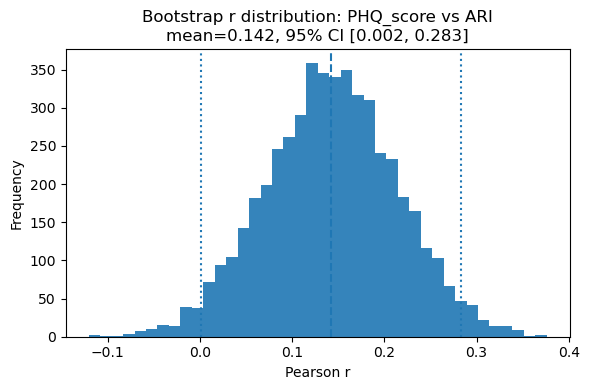

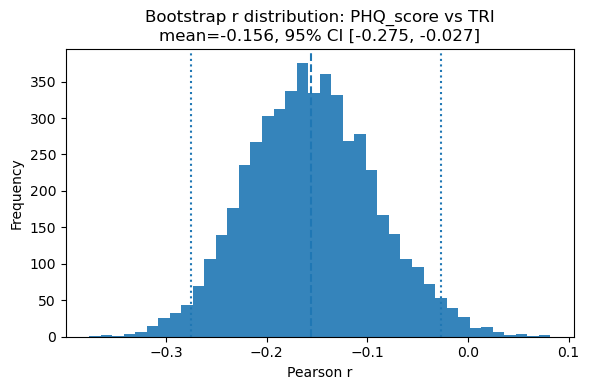

In [19]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

def bootstrap_corr(x, y, n_boot=5000, ci=95, random_state=42):
    rng = np.random.default_rng(random_state)
    x = np.asarray(x); y = np.asarray(y)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]; y = y[mask]
    n = len(x)
    boots = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        r, _ = stats.pearsonr(x[idx], y[idx])
        boots[i] = r
    alpha = (100 - ci) / 2
    lo, hi = np.percentile(boots, [alpha, 100 - alpha])
    return float(boots.mean()), float(lo), float(hi), boots

phq_col_candidates = ["PHQ_score", "PHQ", "PHQ8", "PHQ_8", "PHQ9", "PHQ_9"]
phq_col = next((c for c in phq_col_candidates if c in final.columns), None)
assert phq_col is not None, f"Could not find a PHQ column in {phq_col_candidates}"

pairs = []
if "ARI" in final.columns:
    pairs.append(("ARI", "PHQ ↔ ARI"))
if "TRI" in final.columns:
    pairs.append(("TRI", "PHQ ↔ TRI"))

results = {}
for feature, label in pairs:
    mean_r, lo, hi, boots = bootstrap_corr(final[phq_col], final[feature], n_boot=5000, ci=95, random_state=42)
    results[feature] = (mean_r, lo, hi, boots)
    print(f"{label}: mean r = {mean_r:.3f}, 95% CI [{lo:.3f}, {hi:.3f}]  (n={len(boots)})")

for feature, (mean_r, lo, hi, boots) in results.items():
    plt.figure(figsize=(6,4))
    plt.hist(boots, bins=40, alpha=0.9)
    plt.axvline(mean_r, linestyle="--")
    plt.axvline(lo, linestyle=":")
    plt.axvline(hi, linestyle=":")
    plt.title(f"Bootstrap r distribution: {phq_col} vs {feature}\nmean={mean_r:.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")
    plt.xlabel("Pearson r"); plt.ylabel("Frequency")
    plt.tight_layout(); plt.show()


### Scatter + Least-Squares Line (descriptive)

For each index, we show a scatter plot of **PHQ** vs. index with a simple least-squares line to illustrate directionality. (Descriptive only; inferential stats rely on the bootstrap above.)


**Figure 2.** Scatterplots of PHQ vs. (A) ARI and (B) TRI with least-squares fit lines.  
*Note.* Lines summarize linear trend; shaded regions (if shown) are standard-error bands. Correlation coefficients are reported in the Results section with bootstrap CIs.

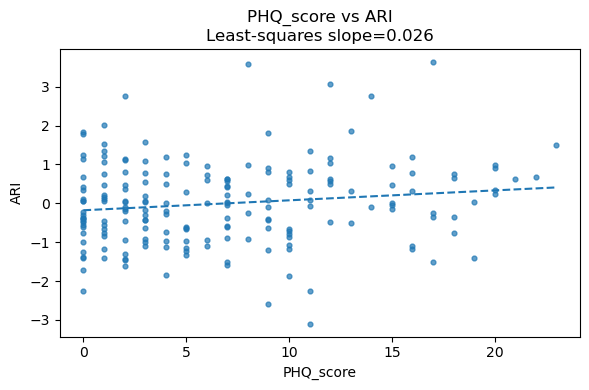

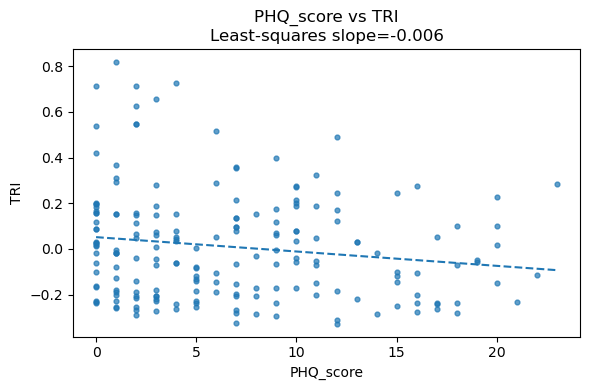

In [20]:

import numpy as np
import matplotlib.pyplot as plt

def scatter_with_ls(x, y, xlab, ylab, title):
    import numpy as np, matplotlib.pyplot as plt
    mask = np.isfinite(x) & np.isfinite(y)
    x = np.asarray(x)[mask]; y = np.asarray(y)[mask]
    if len(x) < 3:
        print("Not enough data to plot", title); return
    b1, b0 = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100); ys = b1*xs + b0
    plt.figure(figsize=(6,4))
    plt.scatter(x, y, s=12, alpha=0.7)
    plt.plot(xs, ys, linestyle="--")
    plt.xlabel(xlab); plt.ylabel(ylab)
    plt.title(title + f"\nLeast-squares slope={b1:.3f}")
    plt.tight_layout(); plt.show()

phq_col_candidates = ["PHQ_score", "PHQ", "PHQ8", "PHQ_8", "PHQ9", "PHQ_9"]
phq_col = next((c for c in phq_col_candidates if c in final.columns), None)

if phq_col and "ARI" in final.columns:
    scatter_with_ls(final[phq_col], final["ARI"], phq_col, "ARI", f"{phq_col} vs ARI")
if phq_col and "TRI" in final.columns:
    scatter_with_ls(final[phq_col], final["TRI"], phq_col, "TRI", f"{phq_col} vs TRI")

### Visualization of Prosodic Responsivity Patterns
**Figure 3.** Distribution of the **Affective Responsivity Index (ARI)** across PHQ Severity Bands. 
*Note.* Higher ARI indicates greater within-speaker variability in F0 and loudness. Boxes/violins depict central tendency and dispersion within PHQ bands; whiskers indicate the interquartile ranges. Bands follow recognized PHQ thresholds (0-4, 5-9, 10-14, 15-19, 20-27).

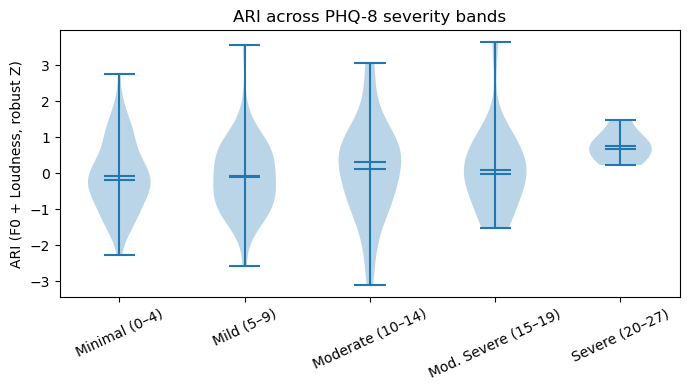

In [21]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd
phq_col_candidates = ['PHQ_score','PHQ','PHQ8','PHQ_8','PHQ9','PHQ_9']
phq_col = next((c for c in phq_col_candidates if c in final.columns), None)
assert phq_col is not None, 'PHQ column not found.'
if 'PHQ_band' not in final.columns:
    final['PHQ_band'] = pd.cut(final[phq_col], bins=[-1,4,9,14,19,27],
        labels=['Minimal (0–4)','Mild (5–9)','Moderate (10–14)','Mod. Severe (15–19)','Severe (20–27)'])
bands = [b for b in final['PHQ_band'].cat.categories] if hasattr(final['PHQ_band'],'cat') else sorted(final['PHQ_band'].dropna().unique())
data = [final.loc[final['PHQ_band']==b,'ARI'].dropna().values for b in bands]
plt.figure(figsize=(7,4))
plt.violinplot(data, showmeans=True, showextrema=True, showmedians=True)
plt.xticks(range(1,len(bands)+1), bands, rotation=25)
plt.ylabel('ARI (F0 + Loudness, robust Z)')
plt.title('ARI across PHQ-8 severity bands')
plt.tight_layout(); plt.show()

**Figure 4.** Distribution of the **Temporal Responsivity Index (TRI)** across PHQ severity bands.  
*Note.* Higher TRI reflects more adaptive pausing dynamics (longer/shorter pauses and speech–pause balance). Interpretation should consider potential floor effects in minimally depressed participants.

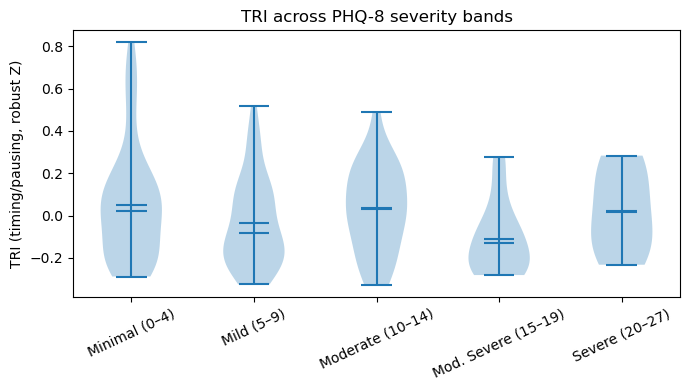

In [22]:
import numpy as np, matplotlib.pyplot as plt
bands = [b for b in final['PHQ_band'].cat.categories] if hasattr(final['PHQ_band'],'cat') else sorted(final['PHQ_band'].dropna().unique())
data = [final.loc[final['PHQ_band']==b,'TRI'].dropna().values for b in bands]
plt.figure(figsize=(7,4))
plt.violinplot(data, showmeans=True, showextrema=True, showmedians=True)
plt.xticks(range(1,len(bands)+1), bands, rotation=25)
plt.ylabel('TRI (timing/pausing, robust Z)')
plt.title('TRI across PHQ-8 severity bands')
plt.tight_layout(); plt.show()

**Figure 5:** Intercorrelations among PHQ, ARI, and TRI (Pearson r). Related but distinct variance is expected. The correlations between PHQ, ARI, and TRI are modest in this sample. This likely reflects the limited number of participants with clinically significant depressive symptoms in the DAIC-WOZ dataset. Accordingly, these coeficients should be interpreted as illustrative rather than diagnostic of affective responsivity.

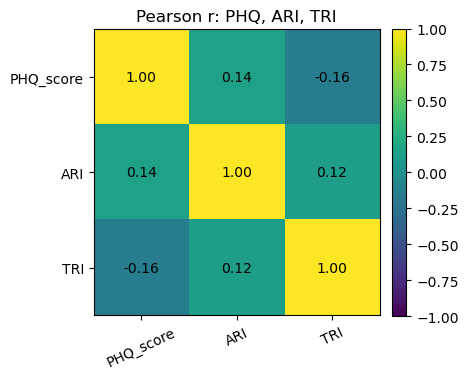

In [23]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd
phq_col_candidates = ['PHQ_score','PHQ','PHQ8','PHQ_8','PHQ9','PHQ_9']
phq_col = next((c for c in phq_col_candidates if c in final.columns), None)
cols = [c for c in [phq_col, 'ARI', 'TRI'] if c in final.columns]
assert len(cols) >= 2, 'Need at least two columns among PHQ/ARI/TRI.'
df = final[cols].replace([np.inf,-np.inf], np.nan).dropna()
corr = df.corr(method='pearson').values
labels = df.columns.tolist()
plt.figure(figsize=(4.6,4))
im = plt.imshow(corr, vmin=-1, vmax=1)
plt.xticks(range(len(labels)), labels, rotation=25)
plt.yticks(range(len(labels)), labels)
plt.colorbar(im, fraction=0.046, pad=0.04)
for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, f'{corr[i,j]:.2f}', ha='center', va='center')
plt.title('Pearson r: PHQ, ARI, TRI')
plt.tight_layout(); plt.show()


### Exploratory compact model (descriptive; not specified *a priori*)

To provide a compact summary of associations, we fit a simple linear model predicting **PHQ** from **ARI** and **TRI** (illustrative only). Results should be interpreted as **descriptive/contextual**, not confirmatory.


In [24]:

import numpy as np
import pandas as pd
import statsmodels.api as sm

phq_col_candidates = ["PHQ_score","PHQ","PHQ8","PHQ_8","PHQ9","PHQ_9"]
phq_col = next((c for c in phq_col_candidates if c in final.columns), None)
cols = [c for c in [phq_col, "ARI", "TRI"] if c in final.columns]
dfm = final[cols].replace([np.inf,-np.inf], np.nan).dropna()
y = dfm[phq_col]
X = dfm[[c for c in ["ARI","TRI"] if c in dfm.columns]]
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              PHQ_score   R-squared:                       0.051
Model:                            OLS   Adj. R-squared:                  0.041
Method:                 Least Squares   F-statistic:                     4.981
Date:                Mon, 13 Oct 2025   Prob (F-statistic):            0.00781
Time:                        12:55:57   Log-Likelihood:                -598.98
No. Observations:                 189   AIC:                             1204.
Df Residuals:                     186   BIC:                             1214.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.7937      0.422     16.082      0.0

## Summary of Findings
- The **Affective Responsivity Index (ARI)** captures robust within-person variability in prosodic expressivity.
- The reduced 2-feature version (**F0 + Loudness**) explains similar variance to the 4-feature version and was used in the final computing of the ARI indice for parsimony.
- The **Temporal Responsivity Index (TRI)** quantifies adaptability of timing dynamics (pausing behavior).
- ARI and TRI are partially independent, reflecting distinct subdomains of prosodic regulation.
- Correlation magnitudes were modest in this sample, consistent with lower severity datasets. These preliminary findings support the construct validity of ARI/TRI while motivating validation in larger, clinically diverse cohorts.


## Future Directions
- ARI and TRI can be extended longitudinally to track within-subject change across sessions.
- The addition of sentiment analysis on transcripts would enable derivation of an **Affective Adaptivity Index (AAI)**.
- Combining ARI, TRI, and AAI into a multimodal framework would allow the ability to measure the effect of changes in sentiment on prosodic expressivity.
- Mixed-effects or survival/time-to-repair models are recommended for synchrony recovery.
- These constructs should be validated on larger, clinically diverse datasets.

### Author’s Notes and Acknowledgments
**Data access.** DAIC–WOZ data were analyzed under a data-use agreement with USC ICT; raw audio and transcripts are not redistributed here. The notebook provides a **synthetic-data mode** (`USE_SYNTHETIC=True`) to enable safe execution without restricted data.

**Code provenance.** Portions of preprocessing, refactoring, and debugging were assisted by generative AI (ChatGPT) under the author’s supervision. All statistical analyses were formulated, interpreted and validated by the author.

**Reproducibility.** Random seeds are fixed for bootstrap estimates. Software versions are documented in `requirements.txt`. The repository will be archived with a **Zenodo DOI** and linked in the manuscript’s “Code and Data Availability” statement.



## Automated Sanity Checks (quick validation)

This cell runs a few fast checks to help verify that the pipeline executed sensibly:

- required columns exist (PHQ, ARI, TRI)  
- values are finite / not constant  
- basic distribution checks (PHQ bands populated)  
- quick Pearson *r* and a small, seeded bootstrap for reproducibility  
- summary status at the end  


In [25]:

import numpy as np
import pandas as pd
from scipy import stats

def _ok(flag, msg):
    icon = "✅" if flag else "❌"
    print(f"{icon} {msg}")
    return flag

all_good = True

# 1) Required columns
phq_candidates = ["PHQ_score","PHQ","PHQ8","PHQ_8","PHQ9","PHQ_9"]
phq_col = next((c for c in phq_candidates if c in final.columns), None)
all_good &= _ok(phq_col is not None, f"PHQ column present ({phq_col})")

for needed in ["ARI","TRI"]:
    all_good &= _ok(needed in final.columns, f"{needed} present")

# 2) Finite / not constant
def _finite_nonconstant(s, name):
    if s is None:
        return False
    vals = pd.to_numeric(s, errors="coerce")
    m = np.isfinite(vals)
    cond = m.sum() > 5 and np.nanstd(vals) > 1e-8
    return _ok(cond, f"{name}: finite values and non-constant (n={m.sum()}, std={np.nanstd(vals):.4f})")

if phq_col:
    all_good &= _finite_nonconstant(final[phq_col], phq_col)
if "ARI" in final.columns:
    all_good &= _finite_nonconstant(final["ARI"], "ARI")
if "TRI" in final.columns:
    all_good &= _finite_nonconstant(final["TRI"], "TRI")

# 3) PHQ band distribution (if available)
if "PHQ_band" in final.columns:
    counts = final["PHQ_band"].value_counts(dropna=True).sort_index()
    print("📊 PHQ_band counts:\n", counts.to_string())
    all_good &= _ok(counts.sum() >= 20, "PHQ_band has sufficient rows (>=20)")
else:
    print("ℹ No PHQ_band column found; skipping band distribution check.")

# 4) Quick Pearson r and mini bootstrap (seeded) for reproducibility
def _pearson(x, y):
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 6:
        return np.nan, np.nan
    r, p = stats.pearsonr(x[mask], y[mask])
    return r, p

if phq_col and "ARI" in final.columns:
    r, p = _pearson(final[phq_col].to_numpy(), final["ARI"].to_numpy())
    print(f"🔎 Pearson r (PHQ vs ARI): r={r:.3f}  p={p:.4f}" if np.isfinite(r) else "PHQ vs ARI: insufficient data")

if phq_col and "TRI" in final.columns:
    r, p = _pearson(final[phq_col].to_numpy(), final["TRI"].to_numpy())
    print(f"🔎 Pearson r (PHQ vs TRI): r={r:.3f}  p={p:.4f}" if np.isfinite(r) else "PHQ vs TRI: insufficient data")

# Mini bootstrap for reproducibility
def _mini_boot(x, y, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]; y = y[mask]
    if len(x) < 6: 
        return np.array([])
    out = np.empty(n_boot, dtype=float)
    n = len(x)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        out[i] = stats.pearsonr(x[idx], y[idx])[0]
    return out

if phq_col and "ARI" in final.columns:
    boots = _mini_boot(final[phq_col].to_numpy(), final["ARI"].to_numpy(), 500, 42)
    if boots.size > 0:
        lo, hi = np.percentile(boots, [2.5, 97.5])
        print(f"🧪 Mini-bootstrap (PHQ vs ARI, n=500): 95% CI [{lo:.3f}, {hi:.3f}]")
        all_good &= _ok(np.isfinite(lo) and np.isfinite(hi), "Mini-bootstrap CI computed (PHQ vs ARI)")

if phq_col and "TRI" in final.columns:
    boots = _mini_boot(final[phq_col].to_numpy(), final["TRI"].to_numpy(), 500, 42)
    if boots.size > 0:
        lo, hi = np.percentile(boots, [2.5, 97.5])
        print(f"🧪 Mini-bootstrap (PHQ vs TRI, n=500): 95% CI [{lo:.3f}, {hi:.3f}]")
        all_good &= _ok(np.isfinite(lo) and np.isfinite(hi), "Mini-bootstrap CI computed (PHQ vs TRI)")

print("\n" + ("✅ All core validation checks passed." if all_good else "⚠ Some checks failed; review outputs above."))


✅ PHQ column present (PHQ_score)
✅ ARI present
✅ TRI present
✅ PHQ_score: finite values and non-constant (n=189, std=5.9084)
✅ ARI: finite values and non-constant (n=189, std=1.0639)
✅ TRI: finite values and non-constant (n=189, std=0.2360)
📊 PHQ_band counts:
 PHQ_band
Minimal (0–4)          86
Mild (5–9)             46
Moderate (10–14)       30
Mod. Severe (15–19)    20
Severe (20–27)          7
✅ PHQ_band has sufficient rows (>=20)
🔎 Pearson r (PHQ vs ARI): r=0.142  p=0.0516
🔎 Pearson r (PHQ vs TRI): r=-0.157  p=0.0306
🧪 Mini-bootstrap (PHQ vs ARI, n=500): 95% CI [0.006, 0.282]
✅ Mini-bootstrap CI computed (PHQ vs ARI)
🧪 Mini-bootstrap (PHQ vs TRI, n=500): 95% CI [-0.265, -0.031]
✅ Mini-bootstrap CI computed (PHQ vs TRI)

✅ All core validation checks passed.


### Optional Synthetic Data Generator (for Reproducibility Only)

> This optional cell allows reviewers to test the full pipeline without access to the restricted DaySWAS dataset. 
> It generates a small synthetic dataset with the same column structure (PHQ, ARI, TRI) to verify that the 
> notebook runs end-to-end. This synthetic data is not used in any analyses or reported results.
> Set `USE_SYNTHETIC = True` to run this notebook without DAIC‑WOZ access. This mode generates a small, schema‑compatible fake dataset so collaborators/reviewers can execute the pipeline without breaching data‑use agreements. Set `USE_SYNTHETIC = False` (default) to use real data. 

In [1]:

# --- Synthetic Data Toggle (for safe, shareable execution) ---
USE_SYNTHETIC = False  # Change to True to run without DAIC‑WOZ data

if USE_SYNTHETIC:
    import numpy as np, pandas as pd
    np.random.seed(42)
    n = 250
    # Minimal schema compatible with downstream steps (rename PHQ as needed downstream if different)
    final = pd.DataFrame({
        "PHQ": np.random.randint(0, 27, n),
        "F0_SD_robustZ": np.random.normal(0, 1, n),
        "Loud_SD_eGe_robustZ": np.random.normal(0, 1, n),
        "Jitter_eGe_robustZ": np.random.normal(0, 1, n),
        "Shimmer_eGe_robustZ": np.random.normal(0, 1, n),
        "mean_pause_sec_robustZ": np.random.normal(0, 1, n),
        "speech_pause_ratio_robustZ": np.random.normal(0, 1, n),
        "pause_rate_per_min_robustZ": np.random.normal(0, 1, n),
    })
    print("⚙️ Using synthetic data (schema-compatible).")
else:
    print("📂 Using real dataset (ensure DAIC‑WOZ access and loading code above is run).")


📂 Using real dataset (ensure DAIC‑WOZ access and loading code above is run).


In [26]:
# --- Synthetic data toggle ---
USE_SYNTHETIC = False  # set to True to bypass external data and generate a fake dataset

if USE_SYNTHETIC:
    import numpy as np, pandas as pd
    rng = np.random.default_rng(7)
    n = 220  # small, realistic size
    
    # Simulate PHQ with a mild-skew distribution (~0-24)
    phq = np.clip(rng.normal(9.5, 5.0, n), 0, 24)
    
    # Simulate prosodic features with weak correlations to PHQ
    f0_sd = rng.normal(0, 1, n) - 0.05*phq/10.0
    loud_sd = rng.normal(0, 1, n) - 0.04*phq/10.0
    jitter = rng.normal(0, 1, n) + 0.02*phq/10.0
    shimmer = rng.normal(0, 1, n) + 0.02*phq/10.0
    
    # Timing features (TRI components), lightly associated with PHQ
    mean_pause = np.clip(rng.normal(0.8, 0.25, n) + 0.01*phq/10.0, 0.1, 3.0)
    spr = np.clip(rng.normal(1.6, 0.4, n) + 0.02*phq/10.0, 0.3, 3.5)  # speech_pause_ratio
    pr_min = np.clip(rng.normal(12, 3, n) + 0.1*phq/10.0, 2, 40)     # pause_rate_per_min
    
    final = pd.DataFrame({
        "PHQ_score": phq,
        "F0_SD_robustZ": f0_sd,
        "Loud_SD_eGe_robustZ": loud_sd,
        "Jitter_eGe_robustZ": jitter,
        "Shimmer_eGe_robustZ": shimmer,
        "mean_pause_sec": mean_pause,
        "speech_pause_ratio": spr,
        "pause_rate_per_min": pr_min,
    })
    
    print("✅ Synthetic dataset created for validation only. Shape:", final.shape)
    print("Columns:", list(final.columns))

### Results Bundle (Exports)
To streamline submission/review, this block writes a **minimal results bundle** containing the derived indices and PHQ.  
Update paths as needed before running.

In [15]:

# Update export paths as needed
out_csv = r"C:/Users/rache/Downloads/DAICWOZ/data_unzipped/final_indices_minimal.csv"
readme_path = r"C:/Users/rache/Downloads/DAICWOZ/data_unzipped/results_README.txt"

subset_cols = [c for c in ["PHQ_score","ARI","ARI_F0Loud","TRI","AAI"] if c in final.columns]
try:
    final[subset_cols].to_csv(out_csv, index=False)
    with open(readme_path, "w", encoding="utf-8") as f:
        f.write(
            "Minimal results bundle\\n"
            "- Columns: " + ", ".join(subset_cols) + "\\n"
            "- Notes: ARI=affective expressivity (robust Z), TRI=timing/repair composite, AAI=adaptivity to affect if available.\\n"
            "- See notebook for computation details.\\n"
        )
    print("Wrote:", out_csv)
    print("Wrote:", readme_path)
except Exception as e:
    print("Bundle export failed:", e)

Wrote: C:/Users/rache/Downloads/DAICWOZ/data_unzipped/final_indices_minimal.csv
Wrote: C:/Users/rache/Downloads/DAICWOZ/data_unzipped/results_README.txt
